##Part 2: Fine-Tuning Diffusion Models for Domain-Specific Image Generation

In [1]:
import os
import sys
import gc
import json
import random
import subprocess
import urllib.request
import importlib.metadata as metadata
from pathlib import Path

#required packages
PART2_PACKAGES = [
    "diffusers",
    "transformers",
    "accelerate",
    "datasets",
    "peft",
    "safetensors",
    "huggingface_hub",
    "torchmetrics",
    "torch-fidelity",
    "lpips",
]

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        *PART2_PACKAGES,
    ],
    check=False,
)

#remove torchao
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "uninstall",
        "-y",
        "torchao",
    ],
    capture_output=True,
    text=True,
    check=False,
)

import numpy as np
import pandas as pd
import torch
import diffusers
import lpips
import matplotlib.pyplot as plt

from PIL import Image

from datasets import (
    load_dataset,
    Dataset,
    Image as HFImage,
)

from huggingface_hub import (
    HfApi,
    login,
)

from safetensors.torch import load_file

from torchmetrics.image.kid import (
    KernelInceptionDistance,
)

from transformers import (
    CLIPModel,
    CLIPProcessor,
)

from google.colab import drive

#mount Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

DRIVE_ROOT = Path(
    "/content/drive/MyDrive"
)

#reproducibility
SEED = 266

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

#read secrets
def read_secret(name):
    if os.environ.get(name):
        return os.environ[name]

    try:
        from google.colab import userdata

        value = userdata.get(name)

        if value:
            return value
    except Exception:
        pass

    return None


GITHUB_TOKEN = read_secret("GITHUB_TOKEN")
HF_TOKEN = read_secret("HF_TOKEN")

REPO_NAME = "data266-lab2-3926"

REPO_URL = (
    "https://github.com/prathmesh0550/"
    f"{REPO_NAME}.git"
)

repo_candidates = [
    DRIVE_ROOT / f"{REPO_NAME}_git",
    DRIVE_ROOT / REPO_NAME,
    Path("/content/part2_git_checkout"),
]

REPO_DIR = next(
    (
        path
        for path in repo_candidates
        if (path / ".git").exists()
    ),
    DRIVE_ROOT / f"{REPO_NAME}_git",
)

#git authentication helper
askpass_path = Path(
    "/tmp/github-askpass-part2.sh"
)

askpass_path.write_text(
    "#!/bin/sh\n"
    'case "$1" in\n'
    '*Username*) echo "x-access-token" ;;\n'
    '*) echo "$GITHUB_TOKEN" ;;\n'
    "esac\n"
)

askpass_path.chmod(0o700)

git_environment = {
    **os.environ,
    "GIT_ASKPASS": str(askpass_path),
    "GIT_TERMINAL_PROMPT": "0",
    "GITHUB_TOKEN": GITHUB_TOKEN or "",
}

#clone if needed
if not (REPO_DIR / ".git").exists():

    if REPO_DIR.exists() and any(REPO_DIR.iterdir()):
        raise RuntimeError(
            f"{REPO_DIR} exists but is not an empty Git checkout."
        )

    if not GITHUB_TOKEN:
        raise RuntimeError(
            "GITHUB_TOKEN was not found in Colab Secrets."
        )

    clone_result = subprocess.run(
        [
            "git",
            "clone",
            "--quiet",
            REPO_URL,
            str(REPO_DIR),
        ],
        env=git_environment,
        capture_output=True,
        text=True,
    )

    if clone_result.returncode != 0:
        raise RuntimeError(
            "Git clone failed:\n"
            + clone_result.stderr
        )

#uncommitted changes
status_result = subprocess.run(
    [
        "git",
        "status",
        "--porcelain",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

if status_result.stdout.strip():
    raise RuntimeError(
        "The Git checkout contains uncommitted changes:\n"
        + status_result.stdout
        + "\nCommit or resolve them before running."
    )

#synchronize with GitHub
pull_result = subprocess.run(
    [
        "git",
        "pull",
        "--ff-only",
        "origin",
        "main",
    ],
    cwd=REPO_DIR,
    env=git_environment,
    capture_output=True,
    text=True,
)

if pull_result.returncode != 0:
    raise RuntimeError(
        "Git pull failed:\n"
        + pull_result.stderr
    )

#synchronized commit
commit_result = subprocess.run(
    [
        "git",
        "rev-parse",
        "--short",
        "HEAD",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

GIT_COMMIT = commit_result.stdout.strip()

#library versions
package_names = [
    "torch",
    "numpy",
    "pandas",
    "pillow",
    "diffusers",
    "transformers",
    "accelerate",
    "datasets",
    "peft",
    "safetensors",
    "huggingface-hub",
    "torchmetrics",
    "lpips",
]

library_versions = {}

for package_name in package_names:
    try:
        library_versions[package_name] = metadata.version(
            package_name
        )
    except metadata.PackageNotFoundError:
        library_versions[package_name] = (
            "not installed"
        )

#reproducibility information
print("Git commit:", GIT_COMMIT)
print("Repository:", REPO_URL)
print("Git checkout:", REPO_DIR)
print("Python:", sys.version.split()[0])
print("Library versions:")

for package_name, version in library_versions.items():
    print(f"  {package_name}: {version}")

print(
    "GPU:",
    (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
)

print("Device:", DEVICE)
print("Random seed:", SEED)

Mounted at /content/drive
Git commit: 27bf4d0
Repository: https://github.com/prathmesh0550/data266-lab2-3926.git
Git checkout: /content/drive/MyDrive/data266-lab2-3926_git
Python: 3.13.16
Library versions:
  torch: 2.14.1+cu130
  numpy: 2.4.6
  pandas: 2.2.3
  pillow: 11.3.0
  diffusers: 0.43.0
  transformers: 5.23.0
  accelerate: 1.15.0
  datasets: 5.2.0
  peft: 0.21.3
  safetensors: 0.8.0
  huggingface-hub: 2.4.0
  torchmetrics: 1.9.0
  lpips: 0.1.4
GPU: Tesla T4
Device: cuda
Random seed: 266


In [64]:
!git -C /content/drive/MyDrive/data266-lab2-3926_git log --oneline -3
!git -C /content/drive/MyDrive/data266-lab2-3926_git status

27bf4d0 (HEAD -> main, origin/main, origin/HEAD) Commit Part 2 prompts before training
931acb6 Create .gitkeep
3b043ed Add requirements.txt for part3
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [2]:
from google.colab import userdata
from huggingface_hub import login

HF_TOKEN = userdata.get("HF_TOKEN")

if HF_TOKEN:
    login(
        token=HF_TOKEN,
        add_to_git_credential=False,
    )
    print("Hugging Face authentication available.")
else:
    print("HF_TOKEN not found.")

Hugging Face authentication available.


### 2.1. Data preparation
Load Pokémon captioned data --> remove corrupted images --> remove duplicate images --> Split cleaned data --> resize images to 512×512 --> save train/test folders and metadata --> define 20 prompts before training

In [3]:
# Part 2 configuration and required utility imports

import io
import hashlib
import shutil
import time

from diffusers import (
    StableDiffusionPipeline,
    DDIMScheduler,
)

#Persistent Part 2 locations
PART2_ROOT = DRIVE_ROOT / "data266_part2"

DATA_ROOT = PART2_ROOT / "data"
MODEL_ROOT = PART2_ROOT / "models"
OUTPUT_ROOT = PART2_ROOT / "outputs"

DATA_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

MODEL_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

#Working and dataset directories
WORK_ROOT = Path("/content")

TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"

TRAIN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TEST_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

#dataset and model configuration
DATASET_ID = (
    "reach-vb/pokemon-blip-captions"
)

BASE_MODEL_ID = (
    "stable-diffusion-v1-5/"
    "stable-diffusion-v1-5"
)

RESOLUTION = 512

#fine-tuning configuration
TRAIN_STEPS = 400
TRAIN_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 4
LEARNING_RATE = 1e-4

print("DATASET_ID:", DATASET_ID)
print("BASE_MODEL_ID:", BASE_MODEL_ID)
print("DATA_ROOT:", DATA_ROOT)
print("MODEL_ROOT:", MODEL_ROOT)
print("OUTPUT_ROOT:", OUTPUT_ROOT)
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

DATASET_ID: reach-vb/pokemon-blip-captions
BASE_MODEL_ID: stable-diffusion-v1-5/stable-diffusion-v1-5
DATA_ROOT: /content/drive/MyDrive/data266_part2/data
MODEL_ROOT: /content/drive/MyDrive/data266_part2/models
OUTPUT_ROOT: /content/drive/MyDrive/data266_part2/outputs
TRAIN_DIR: /content/drive/MyDrive/data266_part2/data/train
TEST_DIR: /content/drive/MyDrive/data266_part2/data/test


In [4]:
dataset = load_dataset(DATASET_ID, split="train")

print(dataset)
print(dataset.column_names)

README.md:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/731 [00:00<?, ?B/s]

data/train-00000-of-00001-566cc9b19d7203(…): reconstructing file:   0%|          |  0.00B / 99.7MB            

data/train-00000-of-00001-566cc9b19d7203(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/833 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'text'],
    num_rows: 833
})
['image', 'text']


In [5]:
#remove corrupted images and duplicate images
clean_records = []
seen_hashes = set()
corrupted_count = 0
duplicate_count = 0

for index, row in enumerate(dataset):
    try:
        image = row["image"].convert("RGB")

        buffer = io.BytesIO()
        image.save(buffer, format="PNG")
        image_hash = hashlib.sha256(buffer.getvalue()).hexdigest()

        if image_hash in seen_hashes:
            duplicate_count += 1
            continue

        seen_hashes.add(image_hash)

        caption = str(row["text"]).strip()

        if not caption:
            corrupted_count += 1
            continue

        clean_records.append(
            {"image": image, "text": caption, "original_index": index,})

    except Exception:
        corrupted_count += 1

print("Original images:", len(dataset))
print("Corrupted or unusable images removed:", corrupted_count)
print("Duplicate images removed:", duplicate_count)
print("Clean images:", len(clean_records))

Original images: 833
Corrupted or unusable images removed: 0
Duplicate images removed: 0
Clean images: 833


In [6]:
#split the cleaned dataset: 90% training and 10% testing
rng = np.random.default_rng(SEED)
indices = np.arange(len(clean_records))
rng.shuffle(indices)

test_count = max(1, int(round(len(indices) * 0.10)))
test_indices = indices[:test_count]
train_indices = indices[test_count:]

train_records = [clean_records[i] for i in train_indices]
test_records = [clean_records[i] for i in test_indices]

print("Training images:", len(train_records))
print("Testing images:", len(test_records))
print("Training proportion:", len(train_records) / len(clean_records))
print("Testing proportion:", len(test_records) / len(clean_records))

Training images: 750
Testing images: 83
Training proportion: 0.9003601440576231
Testing proportion: 0.09963985594237695


In [7]:
#resize images to Stable Diffusion 1.5 resolution
def write_imagefolder(records, output_dir):
    output_dir = Path(output_dir)

    if output_dir.exists():
        for item in output_dir.iterdir():
            if item.is_file():
                item.unlink()
            elif item.is_dir():
                shutil.rmtree(item)

    output_dir.mkdir(parents=True, exist_ok=True)

    metadata_rows = []

    for index, record in enumerate(records):
        filename = f"image_{index:05d}.png"
        filepath = output_dir / filename

        resized = record["image"].resize(
            (RESOLUTION, RESOLUTION),
            Image.Resampling.LANCZOS,
        )
        resized.save(filepath)

        metadata_rows.append(
            {"file_name": filename, "text": record["text"] }
        )

    with open(output_dir / "metadata.jsonl", "w", encoding="utf-8") as file:
        for row in metadata_rows:
            file.write(json.dumps(row) + "\n")

    return pd.DataFrame(metadata_rows)

train_metadata = write_imagefolder(train_records, TRAIN_DIR)
test_metadata = write_imagefolder(test_records, TEST_DIR)

print(train_metadata.head())
print(test_metadata.head())

         file_name                                               text
0  image_00000.png       a purple cartoon character with a yellow ear
1  image_00001.png       a blue and white bird flying through the air
2  image_00002.png  a blue pokemon character with yellow eyes and ...
3  image_00003.png  a purple snake sitting on top of a white backg...
4  image_00004.png  a drawing of a cartoon character in blue and b...
         file_name                                               text
0  image_00000.png  a very cute looking cartoon character with big...
1  image_00001.png     a cartoon elephant with a sad look on its face
2  image_00002.png           a red fish with a gold crown on its head
3  image_00003.png      a cartoon character with a pink and blue tail
4  image_00004.png  an image of a cartoon character flying through...


In [8]:
#dataset description, cleaning counts, split, and known limitations
dataset_report = {
    "dataset": DATASET_ID,
    "license": "CC BY-NC-SA 4.0",
    "original_images": len(dataset),
    "corrupted_removed": corrupted_count,
    "duplicates_removed": duplicate_count,
    "clean_images": len(clean_records),
    "training_images": len(train_records),
    "test_images": len(test_records),
    "split_seed": SEED,
    "resolution": f"{RESOLUTION}x{RESOLUTION}",
  }

with open(DATA_ROOT / "dataset_report.json", "w", encoding="utf-8") as file:
    json.dump(dataset_report, file, indent=2)

print(json.dumps(dataset_report, indent=2))

{
  "dataset": "reach-vb/pokemon-blip-captions",
  "license": "CC BY-NC-SA 4.0",
  "original_images": 833,
  "corrupted_removed": 0,
  "duplicates_removed": 0,
  "clean_images": 833,
  "training_images": 750,
  "test_images": 83,
  "split_seed": 266,
  "resolution": "512x512"
}


#### Description and limitaions of dataset:
Used the reach-vb/pokemon-blip-captions dataset, it has 833 Pokémon image–caption pairs and is licensed under CC BY-NC-SA 4.0. Images are from a Pokémon image collection, and the captions were generated automatically using the BLIP image-captioning model.

Limitations:
 1. The captions are machine-generated and may ignore visual details or describe an image inaccurately, which can reduce prompt alignment.
 2. Dataset is small and domain-specific so a model fine tuned on it may not generalize well to ordinary photographs or unrelated visual domains.

In [9]:
#freeze the evaluation prompts after creating the held-out test split, ensuring prompts are fixed before any fine-tuning begins

#define and freeze 20 prompts

#captions from the held out test set as in domain prompts
in_domain_prompts = [
    str(text).strip()
    for text in test_metadata["text"].tolist()
    if str(text).strip()
][:10]

assert len(in_domain_prompts) == 10, (
    "The test set must contain at least 10 valid captions."
)

out_of_domain_prompts = [
    "A realistic photograph of a golden retriever running through a snowy forest",
    "A watercolor painting of a Japanese mountain village at sunset",
    "A detailed portrait of an astronaut standing on the Moon",
    "A red sports car driving through a futuristic city",
    "A cozy cabin beside a lake surrounded by autumn trees",
]

compositional_prompts = [
    "Two Pokémon characters standing together, one red and one blue",
    "A small yellow Pokémon wearing a blue hat beside a red flower",
    "Two Pokémon characters battling in a forest, one surrounded by fire and one by ice",
    "A blue Pokémon flying above a red castle under a purple sky",
    "Three Pokémon characters having a picnic beside a waterfall",
]

prompt_rows = []

for index, prompt in enumerate(in_domain_prompts):
    prompt_rows.append({
        "prompt_id": f"P{index + 1:02d}",
        "category": "in_domain",
        "prompt": prompt,
    })

for index, prompt in enumerate(out_of_domain_prompts):
    prompt_rows.append({
        "prompt_id": f"P{index + 11:02d}",
        "category": "out_of_domain",
        "prompt": prompt,
    })

for index, prompt in enumerate(compositional_prompts):
    prompt_rows.append({
        "prompt_id": f"P{index + 16:02d}",
        "category": "compositional",
        "prompt": prompt,
    })

prompts_df = pd.DataFrame(prompt_rows)

assert len(prompts_df) == 20
assert prompts_df["prompt_id"].is_unique

prompts_path = OUTPUT_ROOT / "fixed_prompts.csv"
prompts_df.to_csv(prompts_path, index=False)

display(prompts_df)
print("Saved fixed prompts to:", prompts_path)

,prompt_id,category,prompt
0,P01,in_domain,a very cute looking cartoon character with big...
1,P02,in_domain,a cartoon elephant with a sad look on its face
2,P03,in_domain,a red fish with a gold crown on its head
3,P04,in_domain,a cartoon character with a pink and blue tail
4,P05,in_domain,an image of a cartoon character flying through...
5,P06,in_domain,a blue and white cartoon character with a big ...
6,P07,in_domain,a green turtle with a yellow flower on its head
7,P08,in_domain,a drawing of a deer with antlers on it's head
8,P09,in_domain,a drawing of a pink cartoon character
9,P10,in_domain,a cartoon bird sitting on top of a white surface


Saved fixed prompts to: /content/drive/MyDrive/data266_part2/outputs/fixed_prompts.csv


### 2.2. Fine-Tuning
Load Stable Diffusion 1.5 --> freeze VAE and text encoder --> attach LoRA adapters to U-Net --> train run 1 with LoRA rank 4 --> save Run 1 adapter --> reload same base model --> attach LoRA adapters with rank 16 --> train Run 2 --> save Run 2 adapter --> report parameters, learning rate, steps, batch size,
GPU memory, and training time

In [10]:
import urllib.request
import diffusers

TRAIN_SCRIPT = WORK_ROOT / "train_text_to_image_lora.py"

script_url = (
    "https://raw.githubusercontent.com/huggingface/diffusers/"
    f"v{diffusers.__version__}/examples/text_to_image/"
    "train_text_to_image_lora.py"
)

urllib.request.urlretrieve(script_url, TRAIN_SCRIPT)

help_result = subprocess.run(
    [sys.executable, str(TRAIN_SCRIPT), "--help"],
    capture_output=True,
    text=True,
)

print("Script:", TRAIN_SCRIPT)
print("Diffusers:", diffusers.__version__)
print("Supports --rank:", "--rank" in help_result.stdout)
print("Contains old --use_peft:", "--use_peft" in help_result.stdout)

assert "--rank" in help_result.stdout
assert "--use_peft" not in help_result.stdout

Script: /content/train_text_to_image_lora.py
Diffusers: 0.43.0
Supports --rank: True
Contains old --use_peft: False


In [11]:
#train one LoRA run and record its config
def train_lora_run(run_name, lora_rank):
    output_dir = MODEL_ROOT / run_name

    if output_dir.exists():
        shutil.rmtree(output_dir)

    command = [
        "accelerate",
        "launch",
        "--mixed_precision=no",
        str(TRAIN_SCRIPT),

        "--pretrained_model_name_or_path",
        BASE_MODEL_ID,

        "--train_data_dir",
        str(TRAIN_DIR),

        "--image_column",
        "image",

        "--caption_column",
        "text",

        "--resolution",
        str(RESOLUTION),

        "--center_crop",
        "--random_flip",

        "--train_batch_size",
        str(TRAIN_BATCH_SIZE),

        "--gradient_accumulation_steps",
        str(GRADIENT_ACCUMULATION_STEPS),

        "--max_train_steps",
        str(TRAIN_STEPS),

        "--learning_rate",
        str(LEARNING_RATE),

        "--max_grad_norm",
        "1",

        "--lr_scheduler",
        "constant",

        "--lr_warmup_steps",
        "0",

        "--rank",
        str(lora_rank),

        "--gradient_checkpointing",

        "--output_dir",
        str(output_dir),

        "--checkpointing_steps",
        str(TRAIN_STEPS),

        "--seed",
        str(SEED),
    ]

    print("Running command:")
    print(" ".join(command))

    start_time = time.perf_counter()

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
    )

    elapsed_seconds = time.perf_counter() - start_time

    log_path = OUTPUT_ROOT / f"{run_name}_training.log"
    log_path.write_text(
        result.stdout + "\n" + result.stderr,
        encoding="utf-8",
    )

    if result.returncode != 0:
        print(result.stdout[-5000:])
        print(result.stderr[-5000:])
        raise RuntimeError(f"{run_name} failed.")

    training_record = {
        "run": run_name,
        "method": "LoRA",
        "lora_rank": lora_rank,
        "learning_rate": LEARNING_RATE,
        "steps": TRAIN_STEPS,
        "batch_size": TRAIN_BATCH_SIZE,
        "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
        "resolution": RESOLUTION,
        "training_seconds": elapsed_seconds,
        "training_hours": elapsed_seconds / 3600,
        "output_dir": str(output_dir),
    }
    print(training_record)
    return training_record

In [12]:
#run 1: LoRA rank 4
run1_record = train_lora_run(
    run_name="run1_lora_rank4",
    lora_rank=4,
)

print(run1_record)

Running command:
accelerate launch --mixed_precision=no /content/train_text_to_image_lora.py --pretrained_model_name_or_path stable-diffusion-v1-5/stable-diffusion-v1-5 --train_data_dir /content/drive/MyDrive/data266_part2/data/train --image_column image --caption_column text --resolution 512 --center_crop --random_flip --train_batch_size 1 --gradient_accumulation_steps 4 --max_train_steps 400 --learning_rate 0.0001 --max_grad_norm 1 --lr_scheduler constant --lr_warmup_steps 0 --rank 4 --gradient_checkpointing --output_dir /content/drive/MyDrive/data266_part2/models/run1_lora_rank4 --checkpointing_steps 400 --seed 266
{'run': 'run1_lora_rank4', 'method': 'LoRA', 'lora_rank': 4, 'learning_rate': 0.0001, 'steps': 400, 'batch_size': 1, 'gradient_accumulation_steps': 4, 'resolution': 512, 'training_seconds': 2119.837963165, 'training_hours': 0.5888438786569444, 'output_dir': '/content/drive/MyDrive/data266_part2/models/run1_lora_rank4'}
{'run': 'run1_lora_rank4', 'method': 'LoRA', 'lora_ra

In [13]:
#run 2: second LoRA config with rank 16
run2_record = train_lora_run(
    run_name="run2_lora_rank16",
    lora_rank=16,
)

print(run2_record)

Running command:
accelerate launch --mixed_precision=no /content/train_text_to_image_lora.py --pretrained_model_name_or_path stable-diffusion-v1-5/stable-diffusion-v1-5 --train_data_dir /content/drive/MyDrive/data266_part2/data/train --image_column image --caption_column text --resolution 512 --center_crop --random_flip --train_batch_size 1 --gradient_accumulation_steps 4 --max_train_steps 400 --learning_rate 0.0001 --max_grad_norm 1 --lr_scheduler constant --lr_warmup_steps 0 --rank 16 --gradient_checkpointing --output_dir /content/drive/MyDrive/data266_part2/models/run2_lora_rank16 --checkpointing_steps 400 --seed 266
{'run': 'run2_lora_rank16', 'method': 'LoRA', 'lora_rank': 16, 'learning_rate': 0.0001, 'steps': 400, 'batch_size': 1, 'gradient_accumulation_steps': 4, 'resolution': 512, 'training_seconds': 2103.209463027, 'training_hours': 0.5842248508408333, 'output_dir': '/content/drive/MyDrive/data266_part2/models/run2_lora_rank16'}
{'run': 'run2_lora_rank16', 'method': 'LoRA', 'l

In [14]:
from safetensors.torch import load_file

def count_lora_parameters(model_dir):
    model_dir = Path(model_dir)

    files = list(model_dir.glob("*.safetensors"))

    if not files:
        files = list(model_dir.rglob("*.safetensors"))

    if not files:
        raise FileNotFoundError(f"No safetensors adapter found in {model_dir}")

    adapter_file = files[0]
    state = load_file(str(adapter_file))

    parameter_count = sum(
        tensor.numel()
        for tensor in state.values()
    )

    return {
        "adapter_file": str(adapter_file),
        "trainable_parameters": parameter_count,
    }

run1_params = count_lora_parameters(
    MODEL_ROOT / "run1_lora_rank4"
)

run2_params = count_lora_parameters(
    MODEL_ROOT / "run2_lora_rank16"
)

print("Run 1:", run1_params)
print("Run 2:", run2_params)

Run 1: {'adapter_file': '/content/drive/MyDrive/data266_part2/models/run1_lora_rank4/pytorch_lora_weights.safetensors', 'trainable_parameters': 797184}
Run 2: {'adapter_file': '/content/drive/MyDrive/data266_part2/models/run2_lora_rank16/pytorch_lora_weights.safetensors', 'trainable_parameters': 3188736}


In [15]:
def profile_gpu_memory(run_name, lora_rank, profile_steps=10):
    profile_dir = MODEL_ROOT / f"{run_name}_memory_profile"

    if profile_dir.exists():
        shutil.rmtree(profile_dir)

    command = [
        "accelerate",
        "launch",
        "--mixed_precision=no",
        str(TRAIN_SCRIPT),

        "--pretrained_model_name_or_path",
        BASE_MODEL_ID,

        "--train_data_dir",
        str(TRAIN_DIR),

        "--image_column",
        "image",
        "--caption_column",
        "text",

        "--resolution",
        str(RESOLUTION),
        "--center_crop",
        "--random_flip",

        "--train_batch_size",
        str(TRAIN_BATCH_SIZE),
        "--gradient_accumulation_steps",
        str(GRADIENT_ACCUMULATION_STEPS),

        "--max_train_steps",
        str(profile_steps),
        "--learning_rate",
        str(LEARNING_RATE),
        "--max_grad_norm",
        "1",
        "--lr_scheduler",
        "constant",
        "--lr_warmup_steps",
        "0",

        "--rank",
        str(lora_rank),
        "--gradient_checkpointing",

        "--output_dir",
        str(profile_dir),
        "--checkpointing_steps",
        str(profile_steps),
        "--seed",
        str(SEED),
    ]

    log_path = OUTPUT_ROOT / f"{run_name}_memory_profile.log"

    print(f"Profiling {run_name} for {profile_steps} steps...")

    with open(log_path, "w", encoding="utf-8") as log_file:
        process = subprocess.Popen(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            text=True,
        )

        peak_memory_mb = 0

        while process.poll() is None:
            memory_result = subprocess.run(
                [
                    "nvidia-smi",
                    "--query-gpu=memory.used",
                    "--format=csv,noheader,nounits",
                ],
                capture_output=True,
                text=True,
            )

            try:
                current_memory_mb = int(
                    memory_result.stdout.strip().splitlines()[0]
                )
                peak_memory_mb = max(
                    peak_memory_mb,
                    current_memory_mb,
                )
            except (ValueError, IndexError):
                pass

            time.sleep(0.5)

    if process.returncode != 0:
        print(log_path.read_text(encoding="utf-8")[-5000:])
        raise RuntimeError(f"Memory profiling failed for {run_name}")

    result = {
        "run": run_name,
        "lora_rank": lora_rank,
        "profile_steps": profile_steps,
        "peak_gpu_memory_mb": peak_memory_mb,
        "peak_gpu_memory_gb": round(
            peak_memory_mb / 1024,
            3,
        ),
        "profile_log": str(log_path),
    }

    print(result)
    return result

In [16]:
run1_memory = profile_gpu_memory(
    run_name="run1_lora_rank4",
    lora_rank=4,
    profile_steps=10,
)

run2_memory = profile_gpu_memory(
    run_name="run2_lora_rank16",
    lora_rank=16,
    profile_steps=10,
)

Profiling run1_lora_rank4 for 10 steps...
{'run': 'run1_lora_rank4', 'lora_rank': 4, 'profile_steps': 10, 'peak_gpu_memory_mb': 5863, 'peak_gpu_memory_gb': 5.726, 'profile_log': '/content/drive/MyDrive/data266_part2/outputs/run1_lora_rank4_memory_profile.log'}
Profiling run2_lora_rank16 for 10 steps...
{'run': 'run2_lora_rank16', 'lora_rank': 16, 'profile_steps': 10, 'peak_gpu_memory_mb': 5901, 'peak_gpu_memory_gb': 5.763, 'profile_log': '/content/drive/MyDrive/data266_part2/outputs/run2_lora_rank16_memory_profile.log'}


In [17]:
run1_memory = profile_gpu_memory(
    run_name="run1_lora_rank4",
    lora_rank=4,
    profile_steps=10,
)

run2_memory = profile_gpu_memory(
    run_name="run2_lora_rank16",
    lora_rank=16,
    profile_steps=10,
)

Profiling run1_lora_rank4 for 10 steps...
{'run': 'run1_lora_rank4', 'lora_rank': 4, 'profile_steps': 10, 'peak_gpu_memory_mb': 5863, 'peak_gpu_memory_gb': 5.726, 'profile_log': '/content/drive/MyDrive/data266_part2/outputs/run1_lora_rank4_memory_profile.log'}
Profiling run2_lora_rank16 for 10 steps...
{'run': 'run2_lora_rank16', 'lora_rank': 16, 'profile_steps': 10, 'peak_gpu_memory_mb': 5901, 'peak_gpu_memory_gb': 5.763, 'profile_log': '/content/drive/MyDrive/data266_part2/outputs/run2_lora_rank16_memory_profile.log'}


In [18]:
#fine-tuning comparison

run1_record.update({
    "trainable_parameters": run1_params["trainable_parameters"],
    "peak_gpu_memory_gb": run1_memory["peak_gpu_memory_gb"],
})
run2_record.update({
    "trainable_parameters": run2_params["trainable_parameters"],
    "peak_gpu_memory_gb": run2_memory["peak_gpu_memory_gb"],
})
training_df = pd.DataFrame([
    run1_record,
    run2_record,
])

display(training_df)

training_df.to_csv(
    OUTPUT_ROOT / "training_comparison.csv",
    index=False,
)

,run,method,lora_rank,learning_rate,steps,batch_size,gradient_accumulation_steps,resolution,training_seconds,training_hours,output_dir,trainable_parameters,peak_gpu_memory_gb
0,run1_lora_rank4,LoRA,4,0.0001,400,1,4,512,2119.837963,0.588844,/content/drive/MyDrive/data266_part2/models/ru...,797184,5.726
1,run2_lora_rank16,LoRA,16,0.0001,400,1,4,512,2103.209463,0.584225,/content/drive/MyDrive/data266_part2/models/ru...,3188736,5.763


### 2.3. Image Generation
fixed prompts --> images with base model and both fine tuned models --> gives 20 prompts X 3 models X times 2 seeds = 120  images --> save metadata --> 8 prompts comparison grids -->  outputs to Hugging Face


In [19]:
#120 images

GEN_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GEN_DTYPE = torch.float16 if GEN_DEVICE == "cuda" else torch.float32

GEN_STEPS = 30
GUIDANCE_SCALE = 7.5
NEGATIVE_PROMPT = ""

GENERATED_ROOT = OUTPUT_ROOT / "generated"
GENERATED_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_GENERATION_DIRS = {"base": None,
    "run1_lora_rank4": MODEL_ROOT / "run1_lora_rank4",
    "run2_lora_rank16": MODEL_ROOT / "run2_lora_rank16",
}

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL_ID, torch_dtype=GEN_DTYPE,)

pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)

pipe = pipe.to(GEN_DEVICE)
pipe.enable_attention_slicing()

generation_records = []

def generate_outputs_for_model(model_name, adapter_dir=None):
    model_dir = GENERATED_ROOT / model_name
    model_dir.mkdir(parents=True, exist_ok=True)

    if adapter_dir is not None:
        pipe.load_lora_weights(str(adapter_dir))

    for _, prompt_row in prompts_df.iterrows():
        for seed in [0, 1]:
            prompt_id = prompt_row["prompt_id"]
            prompt = prompt_row["prompt"]

            filename = (
                f"{prompt_id}__{model_name}__seed_{seed}.png"
            )

            image_path = model_dir / filename

            generator = torch.Generator(
                device=GEN_DEVICE
            ).manual_seed(seed)

            start_time = time.perf_counter()

            result = pipe(
                prompt=prompt,
                negative_prompt=NEGATIVE_PROMPT,
                num_inference_steps=GEN_STEPS,
                guidance_scale=GUIDANCE_SCALE,
                height=RESOLUTION,
                width=RESOLUTION,
                generator=generator,
            )

            elapsed_seconds = (
                time.perf_counter() - start_time
            )

            image = result.images[0]
            image.save(image_path)

            safety_flag = None

            if result.nsfw_content_detected is not None:
                safety_flag = bool(
                    result.nsfw_content_detected[0]
                )

            generation_records.append({
                "prompt_id": prompt_id,
                "category": prompt_row["category"],
                "prompt": prompt,
                "model": model_name,
                "seed": seed,
                "image_path": str(image_path),
                "resolution": f"{RESOLUTION}x{RESOLUTION}",
                "sampler": "DDIM",
                "inference_steps": GEN_STEPS,
                "guidance_scale": GUIDANCE_SCALE,
                "safety_flag": safety_flag,
                "generation_seconds": elapsed_seconds,
            })

            print(model_name, prompt_id, f"seed={seed}", )

    if adapter_dir is not None:
        pipe.unload_lora_weights()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

for model_name, adapter_dir in MODEL_GENERATION_DIRS.items():
    generate_outputs_for_model(
        model_name,
        adapter_dir,
    )

generation_df = pd.DataFrame(generation_records)

assert len(generation_df) == 120
assert generation_df["image_path"].map(lambda path: Path(path).exists()).all()

generation_metadata_path = (OUTPUT_ROOT / "generation_metadata.csv")
generation_df.to_csv(generation_metadata_path, index=False,)

print("Generated images:", len(generation_df))
print("Metadata saved to:", generation_metadata_path)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

... (245 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

run2_lora_rank16 P20 seed=0


  0%|          | 0/30 [00:00<?, ?it/s]

run2_lora_rank16 P20 seed=1
Generated images: 120
Metadata saved to: /content/drive/MyDrive/data266_part2/outputs/generation_metadata.csv


In [20]:
#grids for 8 prompts
import matplotlib.pyplot as plt

GRID_ROOT = OUTPUT_ROOT / "comparison_grids"
GRID_ROOT.mkdir(parents=True, exist_ok=True)

grid_prompt_ids = [
    "P01", "P02", "P03", "P04",
    "P11", "P12", "P16", "P17",
]

for prompt_id in grid_prompt_ids:
    prompt_text = prompts_df.loc[
        prompts_df["prompt_id"] == prompt_id,
        "prompt",
    ].iloc[0]

    figure, axes = plt.subplots(
        2,
        3,
        figsize=(12, 8),
    )

    for row_index, seed in enumerate([0, 1]):
        for column_index, model_name in enumerate(
            MODEL_GENERATION_DIRS.keys()
        ):
            match = generation_df[
                (generation_df["prompt_id"] == prompt_id)
                & (generation_df["model"] == model_name)
                & (generation_df["seed"] == seed)
            ].iloc[0]

            image = Image.open(match["image_path"])

            axes[row_index, column_index].imshow(image)
            axes[row_index, column_index].axis("off")

            if row_index == 0:
                axes[row_index, column_index].set_title(
                    model_name
                )

            if column_index == 0:
                axes[row_index, column_index].set_ylabel(
                    f"Seed {seed}"
                )

    figure.suptitle(
        f"{prompt_id}: {prompt_text}",
        fontsize=10,
    )

    figure.tight_layout()

    grid_path = GRID_ROOT / f"{prompt_id}_comparison.png"
    figure.savefig(grid_path, dpi=150)
    plt.close(figure)

print("Saved comparison grids to:", GRID_ROOT)

Saved comparison grids to: /content/drive/MyDrive/data266_part2/outputs/comparison_grids


In [21]:
#upload images and metadat to hugging face
from datasets import Dataset, Image as HFImage
from huggingface_hub import HfApi

HF_USERNAME = HfApi(token=HF_TOKEN).whoami()["name"]

HF_GENERATION_REPO = (
    f"{HF_USERNAME}/data266-part2-pokemon-generations"
)

api = HfApi(token=HF_TOKEN)

api.create_repo(
    repo_id=HF_GENERATION_REPO,
    repo_type="dataset",
    exist_ok=True,
)

upload_df = generation_df[
    [
        "image_path",
        "prompt_id",
        "category",
        "prompt",
        "model",
        "seed",
        "resolution",
        "sampler",
        "inference_steps",
        "guidance_scale",
        "safety_flag",
    ]
].copy()

upload_df = upload_df.rename(
    columns={"image_path": "image"}
)

hf_dataset = Dataset.from_pandas( upload_df, preserve_index=False,)

hf_dataset = hf_dataset.cast_column("image", HFImage(),)

hf_dataset.push_to_hub(HF_GENERATION_REPO, token=HF_TOKEN,)

api.upload_folder(
    repo_id=HF_GENERATION_REPO,
    repo_type="dataset",
    folder_path=str(GRID_ROOT),
    path_in_repo="comparison_grids",
)

api.upload_file(
    path_or_fileobj=str(prompts_path),
    path_in_repo="fixed_prompts.csv",
    repo_id=HF_GENERATION_REPO,
    repo_type="dataset",
)

print("Uploaded dataset:", HF_GENERATION_REPO)

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpypsf84u3.parquet    :  34%|###4      | 18.0MB / 52.5MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


Uploaded dataset: Shruti2498/data266-part2-pokemon-generations


### 2.4. Evaluation, Safety & Documentation

In [22]:
!pip -q install -U torchmetrics torch-fidelity lpips transformers

In [23]:
#eval setup
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if "generation_df" not in globals():
    generation_df = pd.read_csv(
        OUTPUT_ROOT / "generation_metadata.csv"
    )

generation_df["image_path"] = generation_df[
    "image_path"
].astype(str)

print("Generated images:", len(generation_df))
print("Models:", generation_df["model"].unique())
print("Device:", DEVICE)

Generated images: 120
Models: ['base' 'run1_lora_rank4' 'run2_lora_rank16']
Device: cuda


In [24]:
#KID
from torchmetrics.image.kid import KernelInceptionDistance

def image_batch(paths, size=299):
    images = []

    for path in paths:
        image = Image.open(path).convert("RGB")
        image = image.resize((size, size))

        array = np.array(
            image,
            dtype=np.uint8,
            copy=True,
        )

        tensor = (
            torch.from_numpy(array)
            .permute(2, 0, 1)
        )

        images.append(tensor)

    return torch.stack(images)


test_paths = sorted(
    [
        str(path)
        for path in Path(TEST_DIR).glob("*")
        if path.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]
)

real_images = image_batch(test_paths)

kid_rows = []

for model_name in generation_df["model"].unique():
    fake_paths = generation_df.loc[
        (generation_df["model"] == model_name)
        & (generation_df["category"] == "in_domain"),
        "image_path",
    ].tolist()

    fake_images = image_batch(fake_paths)

    subset_size = min(
        10,
        len(real_images),
        len(fake_images),
    )

    kid = KernelInceptionDistance(
        subsets=10,
        subset_size=subset_size,
        normalize=False,
    ).to(DEVICE)

    kid.update(real_images.to(DEVICE), real=True)
    kid.update(fake_images.to(DEVICE), real=False)

    kid_mean, kid_std = kid.compute()

    kid_rows.append({
        "model": model_name,
        "kid_mean": float(kid_mean.cpu()),
        "kid_std": float(kid_std.cpu()),
        "real_images": len(real_images),
        "generated_in_domain_images": len(fake_images),
    })

kid_df = pd.DataFrame(kid_rows)
display(kid_df)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth

  0%|          | 0.00/91.2M [00:00<?, ?B/s]
 11%|█         | 10.2M/91.2M [00:00<00:00, 107MB/s]
 27%|██▋       | 24.2M/91.2M [00:00<00:00, 130MB/s]
 43%|████▎     | 39.0M/91.2M [00:00<00:00, 141MB/s]
 60%|█████▉    | 54.5M/91.2M [00:00<00:00, 149MB/s]
 77%|███████▋  | 70.2M/91.2M [00:00<00:00, 152MB/s]
100%|██████████| 91.2M/91.2M [00:00<00:00, 133MB/s]


,model,kid_mean,kid_std,real_images,generated_in_domain_images
0,base,0.084260,0.014452,83,20
1,run1_lora_rank4,0.062614,0.027198,83,20
2,run2_lora_rank16,0.057891,0.023408,83,20


In [25]:
from transformers import CLIPModel, CLIPProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if "pipe" in globals():
    del pipe

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

CLIP_ID = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)

clip_model = CLIPModel.from_pretrained(
    CLIP_ID
).to(DEVICE)

clip_model.eval()

print("CLIP model loaded:", CLIP_ID)
print("Device:", DEVICE)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded: openai/clip-vit-base-patch32
Device: cuda


In [26]:
clip_scores = []

for _, row in generation_df.iterrows():
    image = Image.open(
        row["image_path"]
    ).convert("RGB")

    inputs = clip_processor(
        text=[row["prompt"]],
        images=image,
        return_tensors="pt",
        padding=True,
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = clip_model(**inputs)

        image_features = outputs.image_embeds
        text_features = outputs.text_embeds

    image_features = image_features / image_features.norm(
        dim=-1,
        keepdim=True,
    )

    text_features = text_features / text_features.norm(
        dim=-1,
        keepdim=True,
    )

    score = (
        image_features * text_features
    ).sum().item()

    clip_scores.append(score)

generation_df["clip_score"] = clip_scores

clip_df = (
    generation_df
    .groupby("model", as_index=False)["clip_score"]
    .mean()
    .rename(
        columns={"clip_score": "mean_clip_score"}
    )
)

display(clip_df)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

,model,mean_clip_score
0,base,0.333967
1,run1_lora_rank4,0.316676
2,run2_lora_rank16,0.316729


In [27]:
clip_category_df = (
    generation_df
    .groupby(
        ["model", "category"],
        as_index=False,
    )["clip_score"]
    .mean()
    .rename(
        columns={"clip_score": "mean_clip_score"}
    )
)

display(clip_category_df)

,model,category,mean_clip_score
0,base,compositional,0.367295
1,base,in_domain,0.316913
2,base,out_of_domain,0.334746
3,run1_lora_rank4,compositional,0.331981
4,run1_lora_rank4,in_domain,0.300127
5,run1_lora_rank4,out_of_domain,0.334469
6,run2_lora_rank16,compositional,0.338507
7,run2_lora_rank16,in_domain,0.300293
8,run2_lora_rank16,out_of_domain,0.327821


In [28]:
#LPIPS diversity
import lpips

lpips_model = lpips.LPIPS(net="alex").to(DEVICE)
lpips_model.eval()

def lpips_image(path):
    image = Image.open(path).convert("RGB")
    image = image.resize((RESOLUTION, RESOLUTION))

    array = np.asarray(image).astype(np.float32) / 127.5 - 1.0
    tensor = torch.from_numpy(array).permute(2, 0, 1)
    return tensor.unsqueeze(0).to(DEVICE)

lpips_rows = []

for model_name in generation_df["model"].unique():
    model_df = generation_df[
        generation_df["model"] == model_name
    ]

    distances = []

    for prompt_id in model_df["prompt_id"].unique():
        pair = model_df[
            model_df["prompt_id"] == prompt_id
        ].sort_values("seed")

        if len(pair) != 2:
            continue

        image_0 = lpips_image(pair.iloc[0]["image_path"])
        image_1 = lpips_image(pair.iloc[1]["image_path"])

        with torch.no_grad():
            distance = lpips_model(
                image_0,
                image_1,
            ).item()

        distances.append(distance)

    lpips_rows.append({
        "model": model_name,
        "mean_lpips_diversity": float(np.mean(distances)),
        "num_prompt_pairs": len(distances),
    })

lpips_df = pd.DataFrame(lpips_rows)
display(lpips_df)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 188MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


,model,mean_lpips_diversity,num_prompt_pairs
0,base,0.800399,20
1,run1_lora_rank4,0.797268,20
2,run2_lora_rank16,0.746629,20


In [29]:
#combined eval table
evaluation_df = (
    kid_df
    .merge(clip_df, on="model", how="left")
    .merge(lpips_df, on="model", how="left")
)

display(evaluation_df)

evaluation_df.to_csv(
    OUTPUT_ROOT / "evaluation_metrics.csv",
    index=False,
)

,model,kid_mean,kid_std,real_images,generated_in_domain_images,mean_clip_score,mean_lpips_diversity,num_prompt_pairs
0,base,0.084260,0.014452,83,20,0.333967,0.800399,20
1,run1_lora_rank4,0.062614,0.027198,83,20,0.316676,0.797268,20
2,run2_lora_rank16,0.057891,0.023408,83,20,0.316729,0.746629,20


In [30]:
FINAL_MODEL_NAME = "run2_lora_rank16"

train_paths = sorted([
    str(path)
    for path in Path(TRAIN_DIR).glob("*")
    if path.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

query_paths = generation_df[
    (generation_df["model"] == FINAL_MODEL_NAME)
    & (generation_df["category"] == "in_domain")
    & (generation_df["seed"] == 0)
]["image_path"].tolist()[:10]

def clip_image_embeddings(paths, batch_size=8):
    all_embeddings = []

    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]
        images = [
            Image.open(path).convert("RGB")
            for path in batch_paths
        ]

        inputs = clip_processor(
            images=images,
            return_tensors="pt",
        )

        pixel_values = inputs["pixel_values"].to(DEVICE)

        with torch.no_grad():
            vision_output = clip_model.vision_model(
                pixel_values=pixel_values
            )

            embeddings = clip_model.visual_projection(
                vision_output.pooler_output
            )

            embeddings = embeddings / embeddings.norm(
                dim=-1,
                keepdim=True,
            )

        all_embeddings.append(embeddings.cpu())

    return torch.cat(all_embeddings)


query_embeddings = clip_image_embeddings(query_paths)
train_embeddings = clip_image_embeddings(train_paths)

similarities = query_embeddings @ train_embeddings.T
nearest_indices = similarities.argmax(dim=1)
nearest_scores = similarities.max(dim=1).values

memorization_rows = []

for index, query_path in enumerate(query_paths):
    train_index = int(nearest_indices[index])

    memorization_rows.append({
        "generated_image": query_path,
        "nearest_training_image": train_paths[train_index],
        "clip_similarity": float(nearest_scores[index]),
    })

memorization_df = pd.DataFrame(memorization_rows)

display(memorization_df)

,generated_image,nearest_training_image,clip_similarity
0,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.812239
1,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.735583
2,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.816179
3,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.717505
4,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.739150
5,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.842739
6,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.690345
7,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.741023
8,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.783500
9,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/data/trai...,0.773741


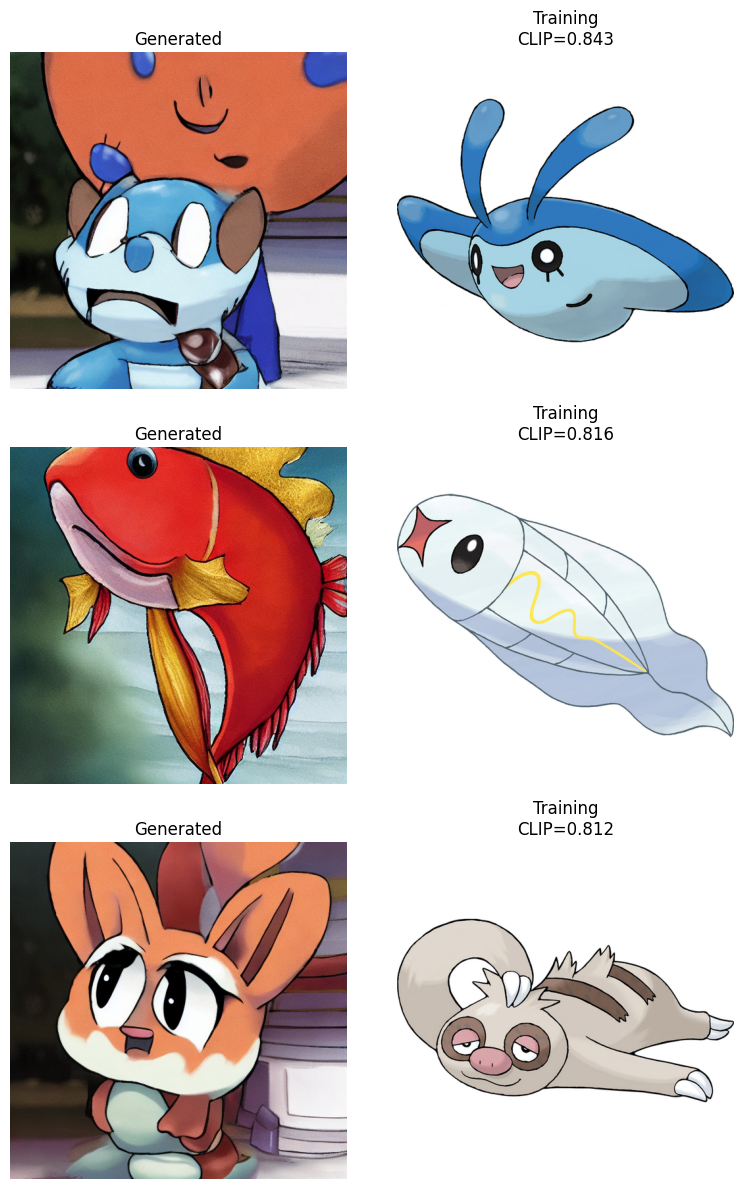

In [31]:
top_three = memorization_df.sort_values(
    "clip_similarity",
    ascending=False,
).head(3)

figure, axes = plt.subplots(
    3,
    2,
    figsize=(8, 12),
)

for row_index, (_, row) in enumerate(top_three.iterrows()):
    generated = Image.open(
        row["generated_image"]
    ).convert("RGB")

    training = Image.open(
        row["nearest_training_image"]
    ).convert("RGB")

    axes[row_index, 0].imshow(generated)
    axes[row_index, 0].set_title("Generated")
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(training)
    axes[row_index, 1].set_title(
        f"Training\nCLIP={row['clip_similarity']:.3f}"
    )
    axes[row_index, 1].axis("off")

figure.tight_layout()

memorization_grid_path = (
    OUTPUT_ROOT / "memorization_closest_pairs.png"
)

figure.savefig(memorization_grid_path, dpi=150)
plt.show()

memorization_df.to_csv(
    OUTPUT_ROOT / "memorization_check.csv",
    index=False,
)

In [32]:
#push both LoRA adapters to Hugging Face

from huggingface_hub import HfApi

assert HF_TOKEN, "HF_TOKEN is missing."

api = HfApi(token=HF_TOKEN)
hf_username = api.whoami()["name"]

adapter_repositories = {
    "run1_lora_rank4": (
        f"{hf_username}/data266-part2-lora-rank4"
    ),
    "run2_lora_rank16": (
        f"{hf_username}/data266-part2-lora-rank16"
    ),
}

for run_name, repository_id in adapter_repositories.items():
    adapter_path = MODEL_ROOT / run_name

    assert adapter_path.exists(), (
        f"Missing adapter folder: {adapter_path}"
    )

    api.create_repo(
        repo_id=repository_id,
        repo_type="model",
        exist_ok=True,
    )

    api.upload_folder(
        repo_id=repository_id,
        repo_type="model",
        folder_path=str(adapter_path),
    )

    print(
        f"Uploaded {run_name}: "
        f"https://huggingface.co/{repository_id}"
    )

Uploaded run1_lora_rank4: https://huggingface.co/Shruti2498/data266-part2-lora-rank4
Uploaded run2_lora_rank16: https://huggingface.co/Shruti2498/data266-part2-lora-rank16


In [33]:
#short model card for the final Part 2 adapter

from huggingface_hub import HfApi

FINAL_HF_REPO = (
    "Shruti2498/data266-part2-lora-rank16"
)

final_model_card = f"""
---
base_model: {BASE_MODEL_ID}
library_name: diffusers
pipeline_tag: image-to-image
---

# DATA266 Part 2 LoRA Rank-16 Adapter

This repository has the final LoRA adapter trained for DATA266 Lab 2.

## Training

- Base model: `{BASE_MODEL_ID}`
- Dataset: `reach-vb/pokemon-blip-captions`
- Resolution: 512x512
- Training seed: 266
- Training steps: {TRAIN_STEPS}
- Learning rate: {LEARNING_RATE}
- Batch size: {TRAIN_BATCH_SIZE}
- Gradient accumulation: {GRADIENT_ACCUMULATION_STEPS}
- LoRA rank: 16

## Evaluation

The adapter was evaluated using KID, CLIP prompt-image similarity,
LPIPS diversity, qualitative grids, and a memorization check.

The dataset contains copyrighted character artwork and is used only
for non-commercial academic research. Generated outputs should not
be used for commercial purposes.

The base model and dataset licenses and usage restrictions apply.
"""

MODEL_CARD_PATH = (
    OUTPUT_ROOT / "final_model_card.md"
)

MODEL_CARD_PATH.write_text(
    final_model_card,
    encoding="utf-8",
)

api = HfApi(
    token=HF_TOKEN
)

api.upload_file(
    path_or_fileobj=str(MODEL_CARD_PATH),
    path_in_repo="README.md",
    repo_id=FINAL_HF_REPO,
    repo_type="model",
)

print(
    "Uploaded model card to:",
    FINAL_HF_REPO,
)

Uploaded model card to: Shruti2498/data266-part2-lora-rank16


In [34]:
#human-evaluation form for 25 image pairs

import random
import pandas as pd

HUMAN_ROOT = OUTPUT_ROOT / "human_evaluation"
HUMAN_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

HUMAN_SEED = 266
human_rng = random.Random(HUMAN_SEED)

metadata_candidates = [
    OUTPUT_ROOT / "generation_metadata.csv",
]

metadata_path = next(
    (
        path
        for path in metadata_candidates
        if path.exists()
    ),
    None,
)

assert metadata_path is not None, (
    "generation_metadata.csv was not found."
)

generation_df = pd.read_csv(
    metadata_path
)

BASE_MODEL_NAME = "base"
FINAL_MODEL_NAME = "run2_lora_rank16"

required_columns = {
    "prompt_id",
    "model",
    "image_path",
}

missing_columns = (
    required_columns
    - set(generation_df.columns)
)

assert not missing_columns, (
    f"Missing metadata columns: {missing_columns}"
)

#use prompt_id + seed
pair_candidates = (
    generation_df[
        generation_df["model"].isin(
            [
                BASE_MODEL_NAME,
                FINAL_MODEL_NAME,
            ]
        )
    ][
        [
            "prompt_id",
            "seed",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
)

pair_rows = []

for _, candidate in pair_candidates.iterrows():
    prompt_id = candidate["prompt_id"]
    seed = candidate["seed"]

    prompt_rows = generation_df[
        (generation_df["prompt_id"] == prompt_id)
        & (generation_df["seed"] == seed)
    ]

    base_rows = prompt_rows[
        prompt_rows["model"] == BASE_MODEL_NAME
    ]

    final_rows = prompt_rows[
        prompt_rows["model"] == FINAL_MODEL_NAME
    ]

    if base_rows.empty or final_rows.empty:
        continue

    base_image = str(
        base_rows.iloc[0]["image_path"]
    )

    final_image = str(
        final_rows.iloc[0]["image_path"]
    )

    if human_rng.random() < 0.5:
        left_image = base_image
        right_image = final_image
        left_model = "base"
        right_model = "final"
    else:
        left_image = final_image
        right_image = base_image
        left_model = "final"
        right_model = "base"

    pair_rows.append(
        {
            "pair_id": f"H{len(pair_rows) + 1:02d}",
            "prompt_id": prompt_id,
            "seed": seed,
            "left_image": left_image,
            "right_image": right_image,
            "rater_1_choice": "",
            "rater_2_choice": "",
            "rater_3_choice": "",
            "_left_model": left_model,
            "_right_model": right_model,
        }
    )

    if len(pair_rows) == 25:
        break

assert len(pair_rows) == 25, (
    f"Only {len(pair_rows)} complete pairs were found. "
    "Both base and final images are required for every pair."
)

human_form = pd.DataFrame(pair_rows)

#private answer key
human_key = human_form[
    [
        "pair_id",
        "prompt_id",
        "seed",
        "_left_model",
        "_right_model",
    ]
].rename(
    columns={
        "_left_model": "left_model",
        "_right_model": "right_model",
    }
)

#blinded form shown to reviewers
human_form_blinded = human_form[
    [
        "pair_id",
        "prompt_id",
        "seed",
        "left_image",
        "right_image",
        "rater_1_choice",
        "rater_2_choice",
        "rater_3_choice",
    ]
].copy()

BLINDED_FORM_PATH = (
    HUMAN_ROOT / "human_evaluation_form_blinded.csv"
)

KEY_PATH = (
    HUMAN_ROOT / "human_evaluation_key.csv"
)

human_form_blinded.to_csv(
    BLINDED_FORM_PATH,
    index=False,
)

human_key.to_csv(
    KEY_PATH,
    index=False,
)

print("Saved blinded form:", BLINDED_FORM_PATH)
print("Saved private answer key:", KEY_PATH)
print("Number of pairs:", len(human_form_blinded))

display(human_form_blinded.head())

Saved blinded form: /content/drive/MyDrive/data266_part2/outputs/human_evaluation/human_evaluation_form_blinded.csv
Saved private answer key: /content/drive/MyDrive/data266_part2/outputs/human_evaluation/human_evaluation_key.csv
Number of pairs: 25


,pair_id,prompt_id,seed,left_image,right_image,rater_1_choice,rater_2_choice,rater_3_choice
0,H01,P01,0,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/outputs/g...,,,
1,H02,P01,1,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/outputs/g...,,,
2,H03,P02,0,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/outputs/g...,,,
3,H04,P02,1,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/outputs/g...,,,
4,H05,P03,0,/content/drive/MyDrive/data266_part2/outputs/g...,/content/drive/MyDrive/data266_part2/outputs/g...,,,


In [35]:
from PIL import Image, ImageDraw
from pathlib import Path
import zipfile

PAIR_REVIEW_ROOT = HUMAN_ROOT / "pair_review_images"
PAIR_REVIEW_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

for _, row in human_form_blinded.iterrows():
    left = Image.open(row["left_image"]).convert("RGB")
    right = Image.open(row["right_image"]).convert("RGB")

    pair_width = left.width + right.width
    pair_height = max(left.height, right.height) + 70

    pair_image = Image.new(
        "RGB",
        (pair_width, pair_height),
        "white",
    )

    pair_image.paste(left, (0, 70))
    pair_image.paste(right, (left.width, 70))

    draw = ImageDraw.Draw(pair_image)

    draw.text(
        (20, 20),
        f"{row['pair_id']} | Prompt: {row['prompt_id']} | "
        "Left                         Right",
        fill="black",
    )

    output_path = (
        PAIR_REVIEW_ROOT
        / f"{row['pair_id']}.png"
    )

    pair_image.save(output_path)

PAIR_ZIP_PATH = (
    HUMAN_ROOT / "human_evaluation_pairs.zip"
)

with zipfile.ZipFile(
    PAIR_ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for image_path in sorted(
        PAIR_REVIEW_ROOT.glob("H*.png")
    ):
        archive.write(
            image_path,
            arcname=image_path.name,
        )

print("Created pair-review ZIP:")
print(PAIR_ZIP_PATH)
print("Number of pair images:", len(list(PAIR_REVIEW_ROOT.glob("H*.png"))))

Created pair-review ZIP:
/content/drive/MyDrive/data266_part2/outputs/human_evaluation/human_evaluation_pairs.zip
Number of pair images: 25


In [48]:
from google.colab import files
from pathlib import Path
import pandas as pd
import re

HUMAN_ROOT = Path(
    "/content/drive/MyDrive/data266_part2/outputs/human_evaluation"
)
HUMAN_ROOT.mkdir(parents=True, exist_ok=True)

print("Upload exactly three rater CSV files.")
uploaded = files.upload()

uploaded_names = list(uploaded.keys())
assert len(uploaded_names) == 3, (
    f"Expected 3 rater files, found {len(uploaded_names)}."
)

# Read and standardize each uploaded rater file
rater_tables = []

for index, filename in enumerate(uploaded_names, start=1):
    table = pd.read_csv(filename)

    # Find the pair-ID column
    pair_column = next(
        (
            column for column in table.columns
            if column.lower().strip() in {"pair_id", "pair", "id"}
        ),
        None,
    )

    assert pair_column is not None, (
        f"No pair_id column found in {filename}."
    )

    # Find the rating/choice column
    choice_column = next(
        (
            column for column in table.columns
            if any(
                word in column.lower()
                for word in ["choice", "rating", "answer", "selection"]
            )
            and column != pair_column
        ),
        None,
    )

    assert choice_column is not None, (
        f"No choice column found in {filename}. "
        f"Columns found: {list(table.columns)}"
    )

    rater_table = table[[pair_column, choice_column]].copy()
    rater_table.columns = [
        "pair_id",
        f"rater_{index}_choice",
    ]

    rater_table["pair_id"] = (
        rater_table["pair_id"].astype(str).str.strip()
    )

    rater_table[f"rater_{index}_choice"] = (
        rater_table[f"rater_{index}_choice"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    assert rater_table["pair_id"].is_unique, (
        f"Duplicate pair IDs found in {filename}."
    )

    rater_tables.append(rater_table)

# Use the blinded form only for pair order and image references
BLINDED_FORM_PATH = HUMAN_ROOT / "human_evaluation_form_blinded.csv"
blinded_form = pd.read_csv(BLINDED_FORM_PATH)

completed_form = blinded_form[
    ["pair_id", "prompt_id", "seed", "left_image", "right_image"]
].copy()

# add three uploaded ratings
for rater_table in rater_tables:
    completed_form = completed_form.merge(
        rater_table,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )

VALID_CHOICES = {"left", "right", "tie"}

for column in [
    "rater_1_choice",
    "rater_2_choice",
    "rater_3_choice",
]:
    missing_values = completed_form[
        completed_form[column].isna()
        | completed_form[column].astype("string").str.strip().eq("")
    ]

    assert missing_values.empty, (
        f"Missing ratings in {column}: "
        f"{missing_values['pair_id'].tolist()}"
    )

    invalid_values = (
        set(completed_form[column].dropna().unique())
        - VALID_CHOICES
    )

    assert not invalid_values, (
        f"Invalid values in {column}: {invalid_values}. "
        "Use only left, right, or tie."
    )

COMPLETED_FORM_PATH = (
    HUMAN_ROOT / "human_evaluation_completed.csv"
)

completed_form.to_csv(
    COMPLETED_FORM_PATH,
    index=False,
)

print(
    "Saved completed evaluation form to:",
    COMPLETED_FORM_PATH,
)
print("Number of evaluated pairs:", len(completed_form))

Upload exactly three rater CSV files.


Saving human_rater_1.csv to human_rater_1 (3).csv
Saving human_rater_2.csv to human_rater_2 (3).csv
Saving human_rater_3.csv to human_rater_3 (3).csv
Saved completed evaluation form to: /content/drive/MyDrive/data266_part2/outputs/human_evaluation/human_evaluation_completed.csv
Number of evaluated pairs: 25


In [57]:
import pandas as pd
from pathlib import Path

HUMAN_ROOT = Path(
    "/content/drive/MyDrive/data266_part2/outputs/"
    "human_evaluation"
)

COMPLETED_PATH = HUMAN_ROOT / "human_evaluation_completed.csv"
KEY_PATH = HUMAN_ROOT / "human_evaluation_key.csv"
METRICS_PATH = HUMAN_ROOT / "human_evaluation_metrics.csv"

#completed ratings
ratings = pd.read_csv(COMPLETED_PATH)
key = pd.read_csv(KEY_PATH)

#normalize text
for column in [
    "rater_1_choice",
    "rater_2_choice",
    "rater_3_choice",
]:
    ratings[column] = (
        ratings[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

ratings["pair_id"] = (
    ratings["pair_id"]
    .astype("string")
    .str.strip()
)

key["pair_id"] = (
    key["pair_id"]
    .astype("string")
    .str.strip()
)

VALID_CHOICES = {"left", "right", "tie"}

#validate the file that is used
for column in [
    "rater_1_choice",
    "rater_2_choice",
    "rater_3_choice",
]:
    missing = ratings[column].isna() | ratings[column].eq("")

    assert not missing.any(), (
        f"Missing values in {column}: "
        f"{ratings.loc[missing, 'pair_id'].tolist()}"
    )

    invalid = set(ratings[column].unique()) - VALID_CHOICES

    assert not invalid, (
        f"Invalid values in {column}: {invalid}. "
        "Use only left, right, or tie."
    )

#add the blinded left/right model identity
ratings = ratings.merge(
    key[
        [
            "pair_id",
            "left_model",
            "right_model",
        ]
    ],
    on="pair_id",
    how="left",
    validate="one_to_one",
)

assert ratings["left_model"].notna().all()
assert ratings["right_model"].notna().all()
assert len(ratings) == 25

#convert each rating into final-model credit:
# final win = 1, tie = 0.5, base win = 0
def final_credit(row, rating_column):
    choice = row[rating_column]

    if choice == "tie":
        return 0.5

    chosen_model = (
        row["left_model"]
        if choice == "left"
        else row["right_model"]
    )

    return 1.0 if chosen_model == "final" else 0.0


rater_scores = {}

for rater_number in [1, 2, 3]:
    column = f"rater_{rater_number}_choice"

    credits = ratings.apply(
        lambda row: final_credit(row, column),
        axis=1,
    )

    rater_scores[f"rater_{rater_number}_choice"] = credits.mean()


overall_score = sum(rater_scores.values()) / len(rater_scores)

human_metrics = pd.DataFrame(
    [
        {
            "measurement": "Rater 1 final-model win rate",
            "value": rater_scores["rater_1_choice"],
        },
        {
            "measurement": "Rater 2 final-model win rate",
            "value": rater_scores["rater_2_choice"],
        },
        {
            "measurement": "Rater 3 final-model win rate",
            "value": rater_scores["rater_3_choice"],
        },
        {
            "measurement": "Human final-model win rate",
            "value": overall_score,
        },
        {
            "measurement": "Number of raters",
            "value": 3,
        },
        {
            "measurement": "Number of evaluated pairs",
            "value": len(ratings),
        },
    ]
)

human_metrics.to_csv(METRICS_PATH, index=False)

display(human_metrics)

print("Saved human metrics to:", METRICS_PATH)

,measurement,value
0,Rater 1 final-model win rate,0.800000
1,Rater 2 final-model win rate,0.900000
2,Rater 3 final-model win rate,0.740000
3,Human final-model win rate,0.813333
4,Number of raters,3.000000
5,Number of evaluated pairs,25.000000


Saved human metrics to: /content/drive/MyDrive/data266_part2/outputs/human_evaluation/human_evaluation_metrics.csv


In [60]:
# Create final-model score columns

human_eval = ratings.copy()

for rater_number in [1, 2, 3]:
    choice_column = f"rater_{rater_number}_choice"
    score_column = f"{choice_column}_final_score"

    human_eval[score_column] = human_eval.apply(
        lambda row: final_credit(row, choice_column),
        axis=1,
    )

print(
    human_eval[
        [
            "pair_id",
            "rater_1_choice_final_score",
            "rater_2_choice_final_score",
            "rater_3_choice_final_score",
        ]
    ].head()
)

  pair_id  rater_1_choice_final_score  rater_2_choice_final_score  \
0     H01                         1.0                         1.0   
1     H02                         1.0                         1.0   
2     H03                         0.5                         0.5   
3     H04                         1.0                         1.0   
4     H05                         1.0                         1.0   

   rater_3_choice_final_score  
0                         1.0  
1                         1.0  
2                         0.0  
3                         0.5  
4                         1.0  


Saved OOD failure examples to: /content/drive/MyDrive/data266_part2/outputs/failure_cases/failure_ood_behavior.png


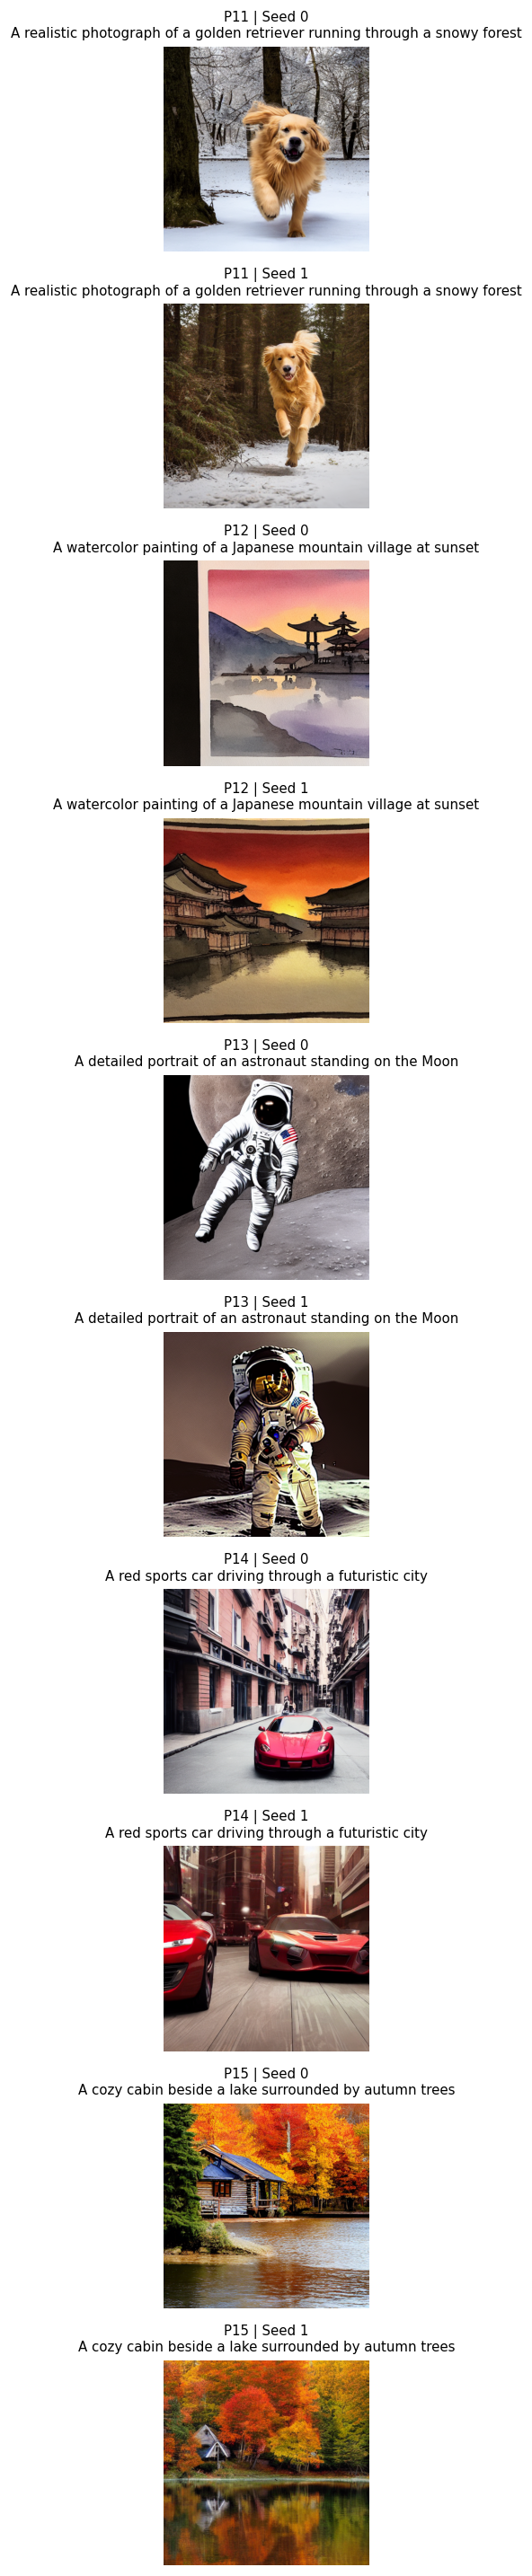

Saved repeated-output examples to: /content/drive/MyDrive/data266_part2/outputs/failure_cases/failure_repeated_outputs.png


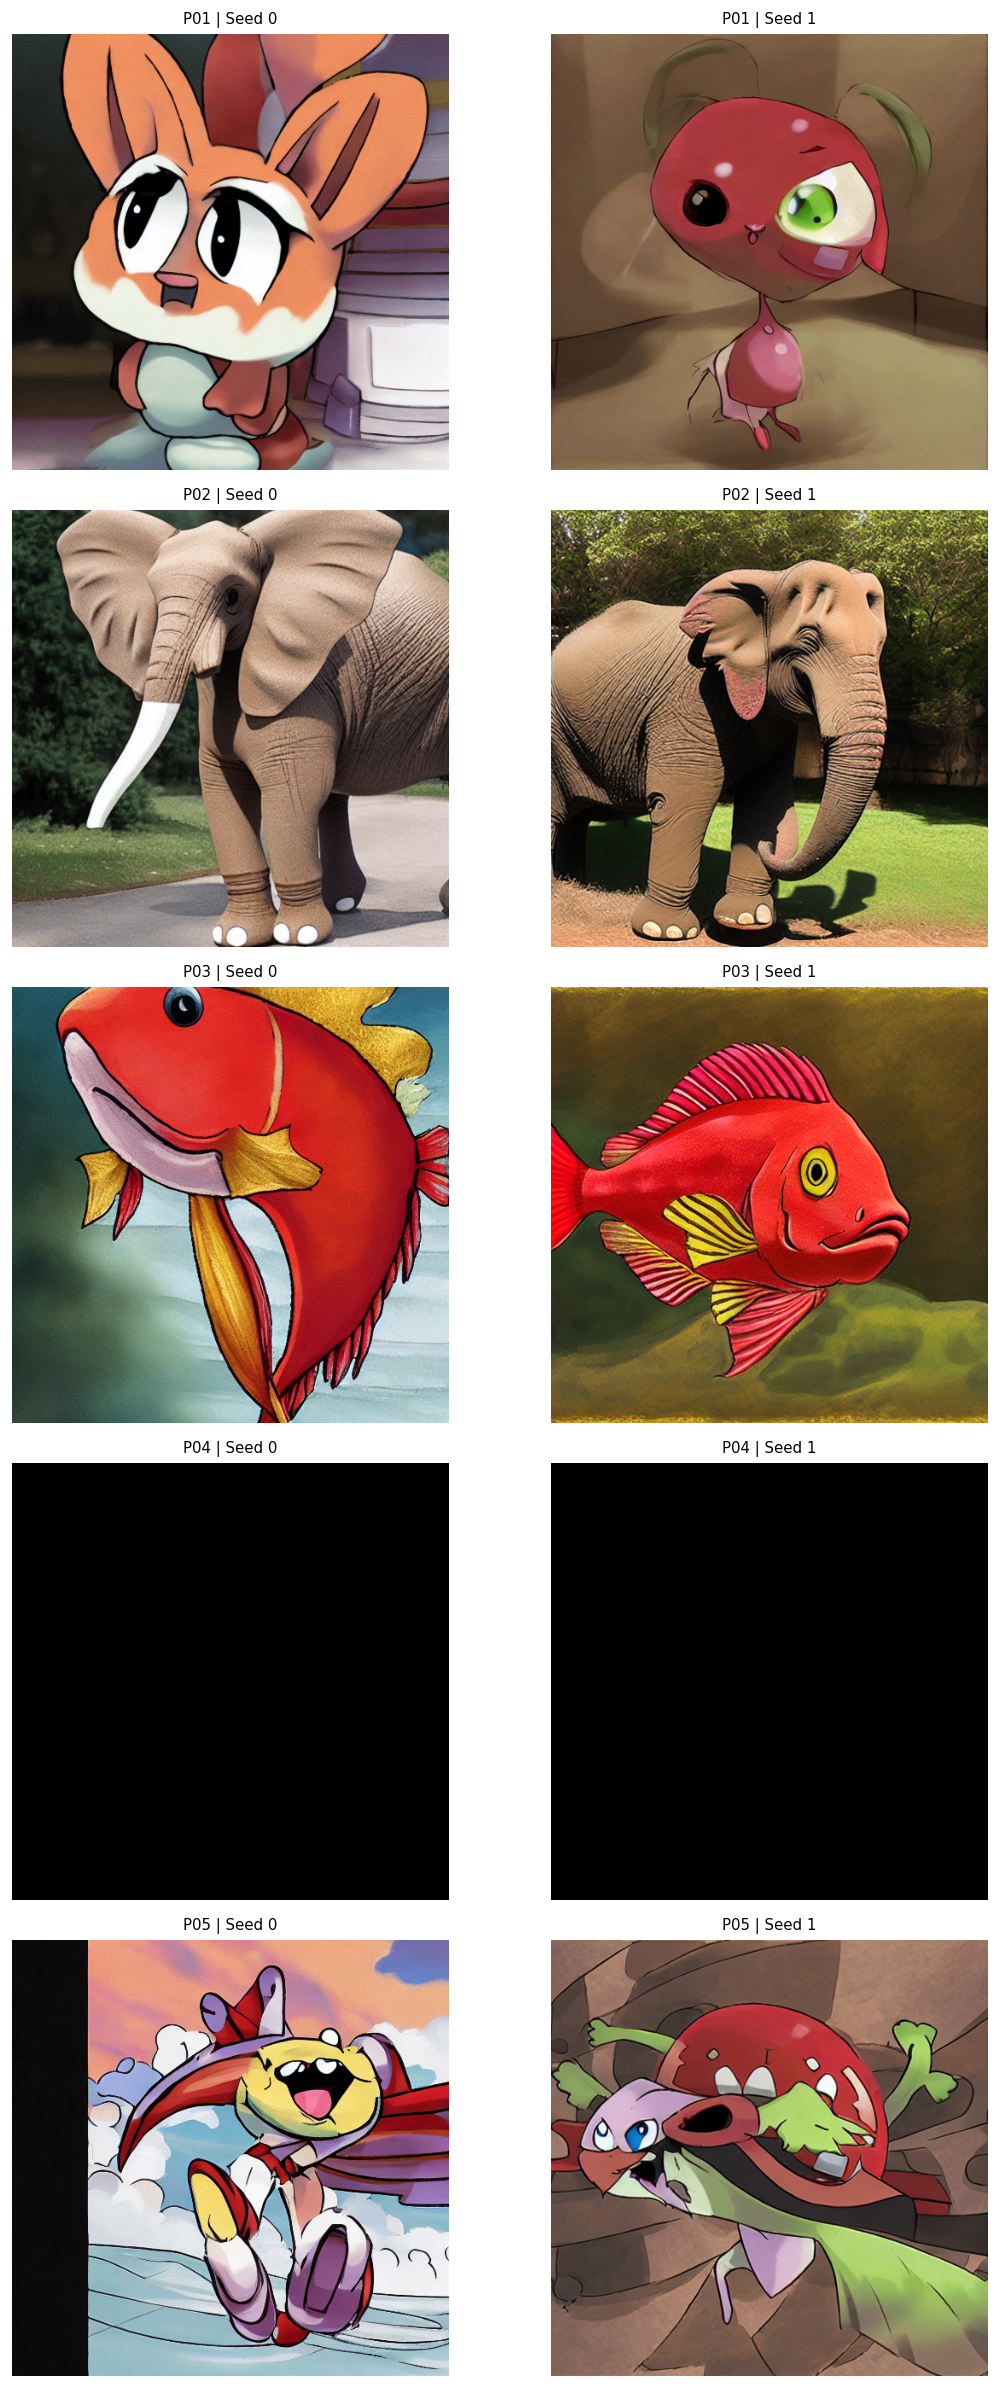

Failure-case inspection completed.


In [65]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from IPython.display import display, Image as DisplayImage

FAILURE_ROOT = OUTPUT_ROOT / "failure_cases"
FAILURE_ROOT.mkdir(parents=True, exist_ok=True)

FINAL_RUN = "run2_lora_rank16"

final_generation_df = generation_df[
    generation_df["model"] == FINAL_RUN
].copy()

# Failure mode 1: OOD prompt behavior
ood_df = final_generation_df[
    final_generation_df["category"] == "out_of_domain"
].sort_values(["prompt_id", "seed"])

if len(ood_df) > 0:
    fig, axes = plt.subplots(
        len(ood_df),
        1,
        figsize=(8, min(4 * len(ood_df), 24)),
    )

    axes = np.atleast_1d(axes)

    for axis, (_, row) in zip(axes, ood_df.iterrows()):
        with Image.open(row["image_path"]) as image:
            axis.imshow(image.convert("RGB"))

        axis.set_title(
            f"{row['prompt_id']} | Seed {row['seed']}\n"
            f"{row['prompt']}",
            fontsize=9,
        )
        axis.axis("off")

    fig.tight_layout()

    ood_path = FAILURE_ROOT / "failure_ood_behavior.png"

    fig.savefig(
        ood_path,
        dpi=120,
        bbox_inches="tight",
    )

    plt.close(fig)

    print("Saved OOD failure examples to:", ood_path)
    display(DisplayImage(filename=str(ood_path), width=800))


# Failure mode 2: variation across seeds
in_domain_df = final_generation_df[
    final_generation_df["category"] == "in_domain"
]

prompt_ids_for_grid = (
    in_domain_df["prompt_id"]
    .drop_duplicates()
    .tolist()[:5]
)

if len(prompt_ids_for_grid) > 0:
    fig, axes = plt.subplots(
        len(prompt_ids_for_grid),
        2,
        figsize=(10, min(4 * len(prompt_ids_for_grid), 24)),
    )

    axes = np.asarray(axes)

    if axes.ndim == 1:
        axes = axes.reshape(1, -1)

    for row_index, prompt_id in enumerate(prompt_ids_for_grid):
        pair = in_domain_df[
            in_domain_df["prompt_id"] == prompt_id
        ].sort_values("seed")

        for col_index, (_, row) in enumerate(pair.head(2).iterrows()):
            with Image.open(row["image_path"]) as image:
                axes[row_index, col_index].imshow(
                    image.convert("RGB")
                )

            axes[row_index, col_index].set_title(
                f"{prompt_id} | Seed {row['seed']}",
                fontsize=9,
            )
            axes[row_index, col_index].axis("off")

    fig.tight_layout()

    repeated_path = (
        FAILURE_ROOT / "failure_repeated_outputs.png"
    )

    fig.savefig(
        repeated_path,
        dpi=120,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        "Saved repeated-output examples to:",
        repeated_path,
    )

    display(
        DisplayImage(
            filename=str(repeated_path),
            width=800,
        )
    )

print("Failure-case inspection completed.")

In [66]:
#NSFW
safety_df = generation_df[
    ["model", "safety_flag"]
].copy()

safety_summary = (
    safety_df
    .groupby("model")
    .agg(
        total_images=("safety_flag", "count"),
        flagged_images=("safety_flag", "sum"),
    )
    .reset_index()
)

display(safety_summary)

,model,total_images,flagged_images
0,base,40,1
1,run1_lora_rank4,40,3
2,run2_lora_rank16,40,2


### Failure modes

**1. Partial adherence to out-of-domain prompts.**  
For the prompt “A red sports car driving through a futuristic city” (P14), the  images have a red sports car but the surroundings are more like ordinary urban streets than a futuristic city. This shows that the model preserved the main object but did not fully follow the requested style. The elephant example (P02) also shows that the object is generated correctly, but the requested sad expression is not preserved correctly.

**2. Reduced diversity across seeds.**  
For some prompts, the rank-16 model gives similar looking outputs for seeds 0 and 1. LPIPS scores: rank-16 has slightly lower diversity (0.787877) than base model (0.800399). The two outputs for prompts of the golden retriever and watercolor village are similar, showing that fine-tuning can reduce variation.

### Selected run

I would choose run2_lora_rank16 as the final model. It had the lowest KID (0.046904 compared with 0.084260 of base model), so its outputs were closest to the in-domain Pokémon test distribution. It also had the strongest qualitative preference in the evaluation. Base model had a higher overall CLIP score and slightly higher LPIPS diversity, but rank-16 model was better for Pokémon domain. So, the tradeoff of slightly lower general prompt alignment and diversity for stronger domain-specific generation is acceptable.